# 03 · Análise Exploratória (EDA)

Descreve **quando, onde e como** ocorrem os sinistros com vítima, sempre comparando
**Campinas × Guarulhos** e **rodovias × vias urbanas**. Como os volumes diferem, as comparações
de perfil usam **% dentro de cada município/tipo de via**.

| Seção | Gráfico | Arquivo |
|---|---|---|
| 1 | Visão geral (tabela) | `03_visao_geral.csv` |
| 2 | Volume anual por tipo de via | `03_volume_anual.png` |
| 3 | Série mensal | `03_serie_mensal.png` + Altair interativo |
| 4 | Dia da semana | `03_dia_semana.png` |
| 5 | Mapa de calor hora × dia | `03_heatmap_hora_dia.png` |
| 6 | Período do dia | `03_periodo_dia.png` |
| 7 | Gravidade por tipo de via | `03_gravidade_por_via.png` |
| 8 | Evolução da % grave/fatal | `03_evolucao_gravidade_anual.png` |
| 9 | Tipos de sinistro | `03_tipos_sinistro.png` |
| 10 | Top vias | `03_top_vias.png` |
| 11 | Veículos e modos: motos, bicicletas, pedestres, pesados | `03_modos_envolvidos.png`, `03_modos_evolucao_anual.png` |

In [1]:
import sys
from pathlib import Path
RAIZ = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(RAIZ))

import polars as pl
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import altair as alt
from src import config, viz

viz.tema()
sin = pl.read_parquet(config.DATA_PROCESSED / "sinistros.parquet").to_pandas()
MUN, VIAS = config.MUNICIPIOS, config.GRUPOS_VIA
print(f"{len(sin):,} sinistros com vítima | {sin.data.min().date()} → {sin.data.max().date()}")

25,858 sinistros com vítima | 2022-01-01 → 2025-12-31


## 1. Visão geral por município e tipo de via

In [2]:
geral = (sin.groupby(["municipio", "grupo_via"])
            .agg(sinistros=("id_sinistro", "count"), graves_fatais=("grave_fatal", "sum"),
                 fatais=("fatal", "sum"))
            .assign(pct_gf=lambda d: (d.graves_fatais / d.sinistros * 100).round(1),
                    pct_fatal=lambda d: (d.fatais / d.sinistros * 100).round(1))
            .reset_index())
viz.salvar_tab(geral, "03_visao_geral")
geral

  ✔ tabela salva: reports/tables/03_visao_geral.csv


,municipio,grupo_via,sinistros,graves_fatais,fatais,pct_gf,pct_fatal
0,CAMPINAS,RODOVIA,3369,746,294,22.1,8.7
1,CAMPINAS,VIA URBANA,9250,1121,274,12.1,3.0
2,GUARULHOS,RODOVIA,4188,466,219,11.1,5.2
3,GUARULHOS,VIA URBANA,9051,1100,329,12.2,3.6


## 2. Volume anual por tipo de via
Contagem de sinistros com vítima por ano. Este é o gráfico-base para discutir o "crescimento"
dos sinistros; o teste formal de tendência está no notebook 04.

  ✔ tabela salva: reports/tables/03_volume_anual.csv


  ✔ figura salva: reports/figures/03_volume_anual.png


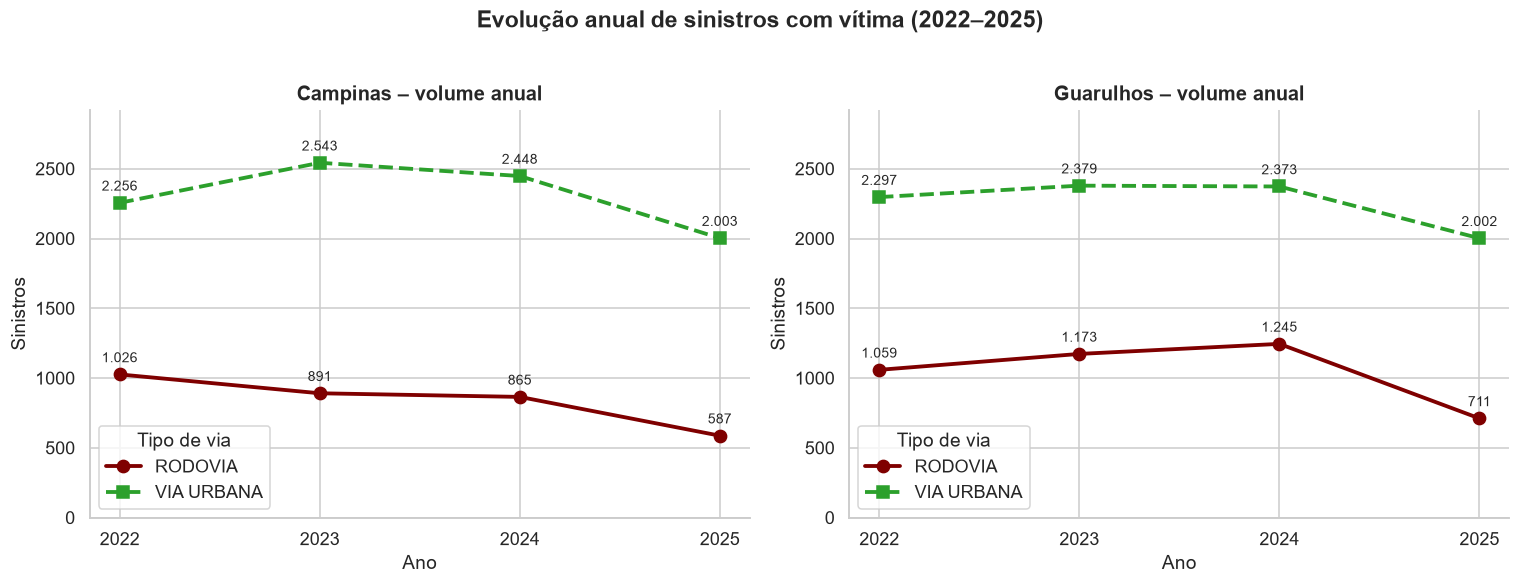

In [3]:
vol = sin.groupby(["municipio", "grupo_via", "ano"]).size().reset_index(name="n")
viz.salvar_tab(vol.pivot_table(index=["municipio", "grupo_via"], columns="ano", values="n").reset_index(),
               "03_volume_anual")
estilo = {"RODOVIA": dict(marker="o", ls="-"), "VIA URBANA": dict(marker="s", ls="--")}
fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))
for ax, mun in zip(axes, MUN):
    for via in VIAS:
        d = vol[(vol.municipio == mun) & (vol.grupo_via == via)]
        ax.plot(d.ano, d.n, color=config.CORES_VIA[via], lw=2.5, ms=8, label=via, **estilo[via])
        for x, y in zip(d.ano, d.n):
            ax.annotate(f"{y:,}".replace(",", "."), (x, y), textcoords="offset points",
                        xytext=(0, 8), ha="center", fontsize=9)
    ax.set(title=f"{mun.title()} – volume anual", xlabel="Ano", ylabel="Sinistros", xticks=config.ANOS)
    ax.set_ylim(0, vol.n.max() * 1.15); ax.legend(title="Tipo de via")
fig.suptitle("Evolução anual de sinistros com vítima (2022–2025)", fontweight="bold", y=1.02)
plt.tight_layout(); viz.salvar_fig(fig, "03_volume_anual"); plt.show()

## 3. Série mensal
Linhas verticais pontilhadas marcam o início de cada ano.

  ✔ figura salva: reports/figures/03_serie_mensal.png


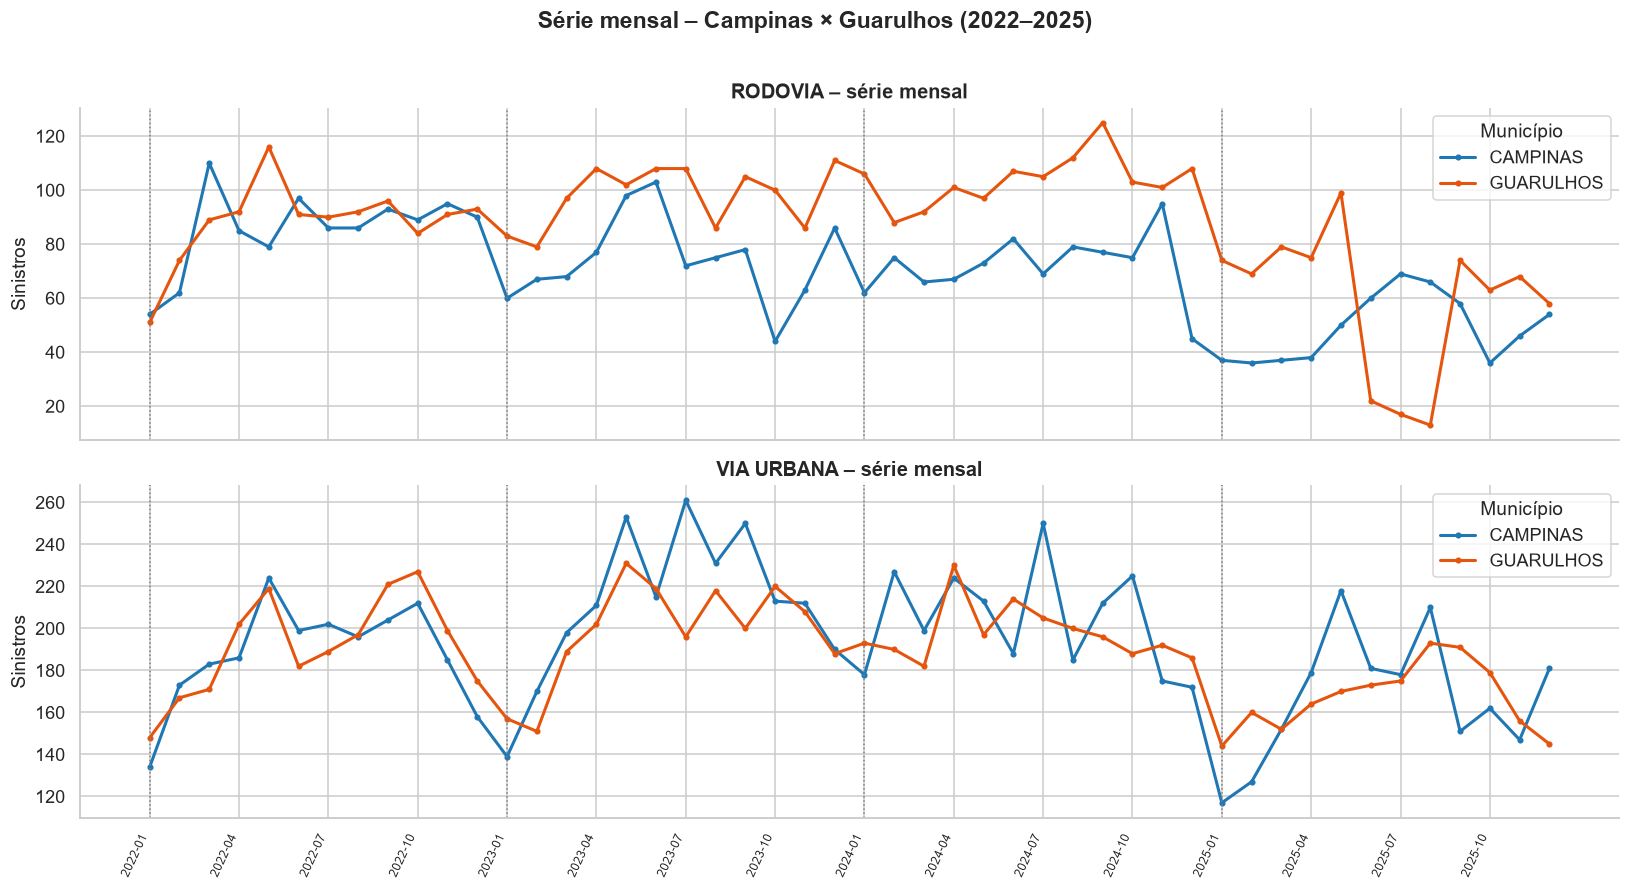

In [4]:
mensal = sin.groupby(["grupo_via", "municipio", "ano_mes"]).size().reset_index(name="n")
meses = sorted(sin.ano_mes.unique())
fig, axes = plt.subplots(2, 1, figsize=(15, 8), sharex=True)
for ax, via in zip(axes, VIAS):
    for mun in MUN:
        d = (mensal[(mensal.grupo_via == via) & (mensal.municipio == mun)]
             .set_index("ano_mes").reindex(meses, fill_value=0))
        ax.plot(meses, d.n, marker="o", ms=3, lw=2, color=config.CORES[mun], label=mun)
    for a in config.ANOS:
        ax.axvline(f"{a}-01", color="gray", ls=":", lw=1)
    ax.set(title=f"{via} – série mensal", ylabel="Sinistros"); ax.legend(title="Município")
axes[1].set_xticks(meses[::3]); axes[1].set_xticklabels(meses[::3], rotation=65, ha="right", fontsize=8)
fig.suptitle("Série mensal – Campinas × Guarulhos (2022–2025)", fontweight="bold", y=1.01)
plt.tight_layout(); viz.salvar_fig(fig, "03_serie_mensal"); plt.show()

**Versão interativa (Altair)** — passe o mouse para ver os valores; salva em
`reports/figures/03_serie_mensal_interativa.html`.

In [5]:
m2 = mensal.assign(data=pd.to_datetime(mensal.ano_mes + "-01"))
sel = alt.selection_point(fields=["municipio"], bind="legend")
graf = (alt.Chart(m2).mark_line(point=True)
        .encode(x=alt.X("data:T", title="Mês"), y=alt.Y("n:Q", title="Sinistros"),
                color=alt.Color("municipio:N", scale=alt.Scale(domain=MUN, range=list(config.CORES.values())),
                                title="Município"),
                opacity=alt.condition(sel, alt.value(1), alt.value(0.15)),
                tooltip=["municipio", "grupo_via", "ano_mes", "n"])
        .properties(width=820, height=220).add_params(sel)
        .facet(row=alt.Row("grupo_via:N", title=None))
        .properties(title="Série mensal de sinistros com vítima – InfoSiga SP (2022–2025)"))
graf.save(str(config.FIG_DIR / "03_serie_mensal_interativa.html"))
graf

alt.FacetChart(...)

## 4. Dia da semana (% dentro de município × via)

  ✔ tabela salva: reports/tables/03_dia_semana.csv


  ✔ figura salva: reports/figures/03_dia_semana.png


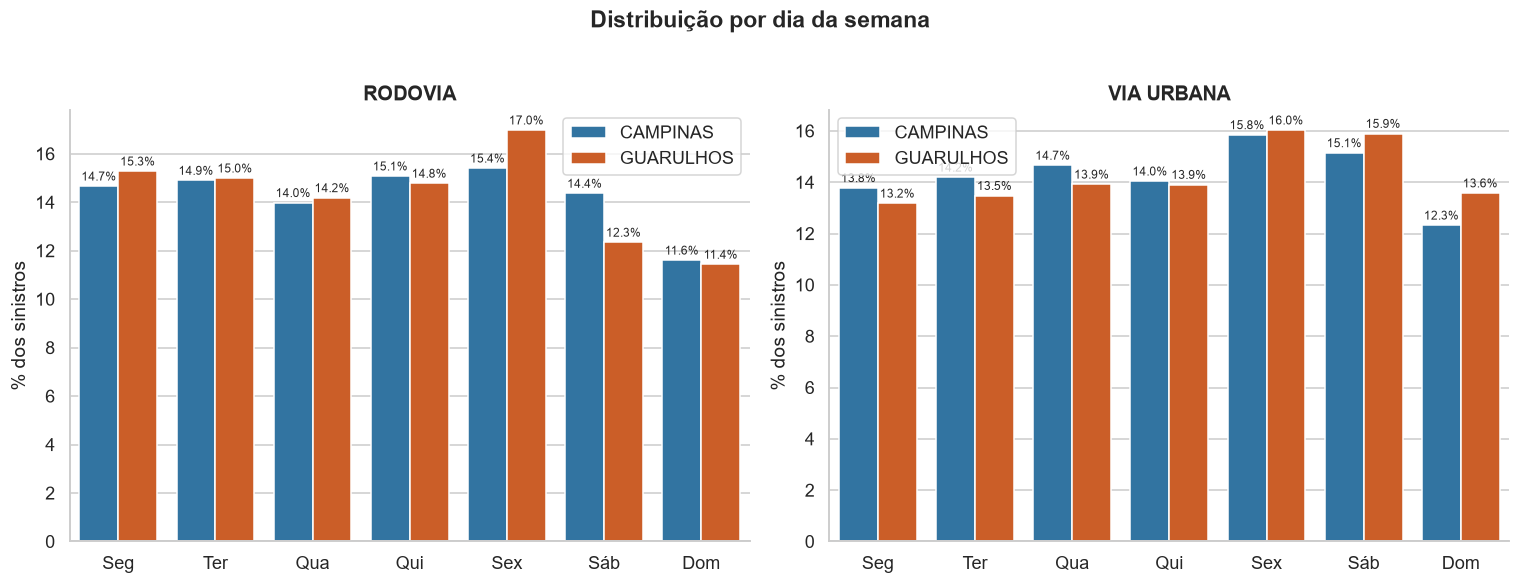

In [6]:
def pct_por(df, col, grupos=("grupo_via", "municipio")):
    t = df.dropna(subset=[col]).groupby(list(grupos) + [col]).size().reset_index(name="n")
    t["pct"] = t.groupby(list(grupos))["n"].transform(lambda x: x / x.sum() * 100)
    return t

dow = pct_por(sin, "dia_semana")
viz.salvar_tab(dow, "03_dia_semana")
fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))
for ax, via in zip(axes, VIAS):
    sns.barplot(data=dow[dow.grupo_via == via], x="dia_semana", y="pct", hue="municipio",
                order=config.ORDEM_DIAS, hue_order=MUN, palette=config.CORES, ax=ax)
    viz.rotulos_pct(ax, fontsize=8)
    ax.set(title=via, xlabel="", ylabel="% dos sinistros"); ax.legend(title="")
fig.suptitle("Distribuição por dia da semana", fontweight="bold", y=1.02)
plt.tight_layout(); viz.salvar_fig(fig, "03_dia_semana"); plt.show()

## 5. Mapa de calor hora × dia da semana
Mesma escala de cor dentro de cada tipo de via (linha), para comparar os municípios.

  ✔ figura salva: reports/figures/03_heatmap_hora_dia.png


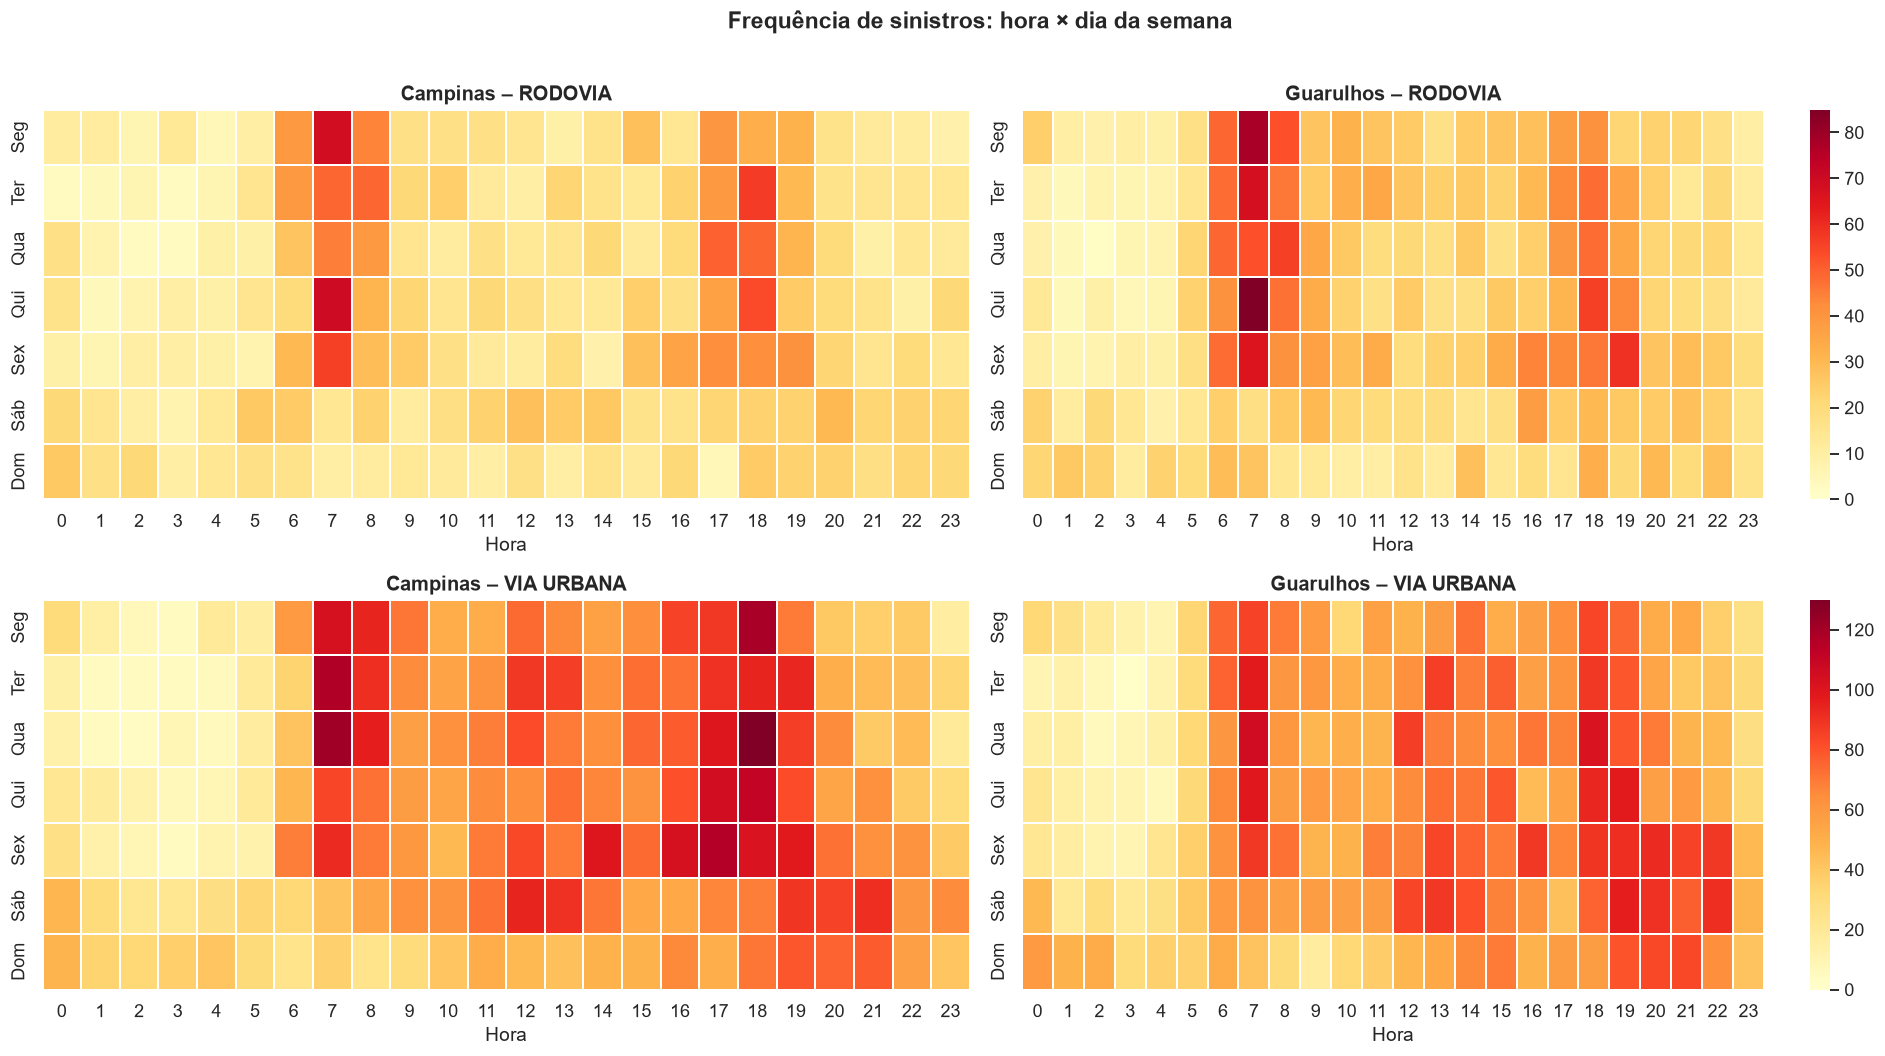

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(18, 9.5))
for i, via in enumerate(VIAS):
    tabs = {}
    for mun in MUN:
        d = sin[(sin.municipio == mun) & (sin.grupo_via == via) & sin.hora_int.notna()]
        tabs[mun] = (d.groupby(["dia_sem_n", "hora_int"]).size().unstack(fill_value=0)
                       .reindex(index=range(1, 8), columns=range(24), fill_value=0))
    vmax = max(t.values.max() for t in tabs.values())
    for j, mun in enumerate(MUN):
        ax = axes[i, j]
        sns.heatmap(tabs[mun], ax=ax, cmap="YlOrRd", vmin=0, vmax=vmax, linewidths=.3,
                    yticklabels=config.ORDEM_DIAS, cbar=(j == 1))
        ax.set(title=f"{mun.title()} – {via}", xlabel="Hora", ylabel="")
fig.suptitle("Frequência de sinistros: hora × dia da semana", fontweight="bold", y=1.01)
plt.tight_layout(); viz.salvar_fig(fig, "03_heatmap_hora_dia"); plt.show()

## 6. Período do dia
Madrugada 0–5h · Manhã 6–11h · Tarde 12–17h · Noite 18–23h (a partir de `hora_sinistro`).

  ✔ tabela salva: reports/tables/03_periodo_dia.csv


  ✔ figura salva: reports/figures/03_periodo_dia.png


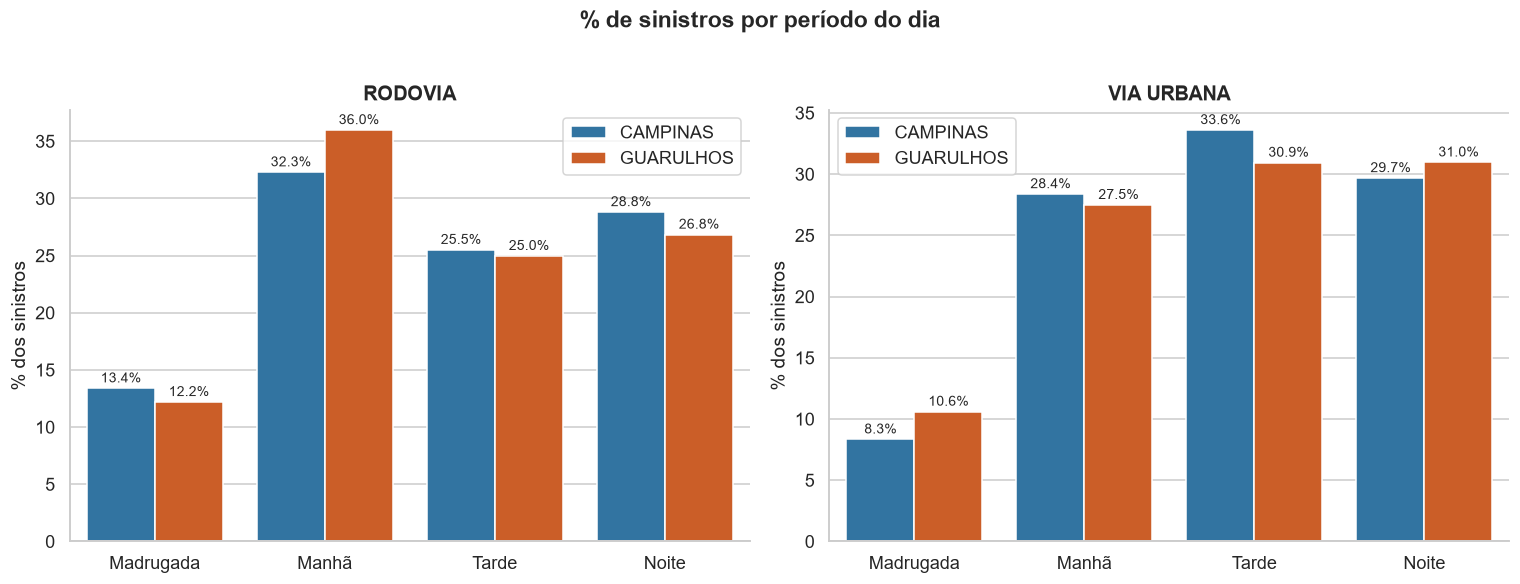

In [8]:
per = pct_por(sin, "periodo")
viz.salvar_tab(per, "03_periodo_dia")
fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))
for ax, via in zip(axes, VIAS):
    sns.barplot(data=per[per.grupo_via == via], x="periodo", y="pct", hue="municipio",
                order=config.ORDEM_PERIODOS, hue_order=MUN, palette=config.CORES, ax=ax)
    viz.rotulos_pct(ax)
    ax.set(title=via, xlabel="", ylabel="% dos sinistros"); ax.legend(title="")
fig.suptitle("% de sinistros por período do dia", fontweight="bold", y=1.02)
plt.tight_layout(); viz.salvar_fig(fig, "03_periodo_dia"); plt.show()

## 7. Gravidade por tipo de via

  ✔ tabela salva: reports/tables/03_gravidade.csv


  ✔ figura salva: reports/figures/03_gravidade_por_via.png


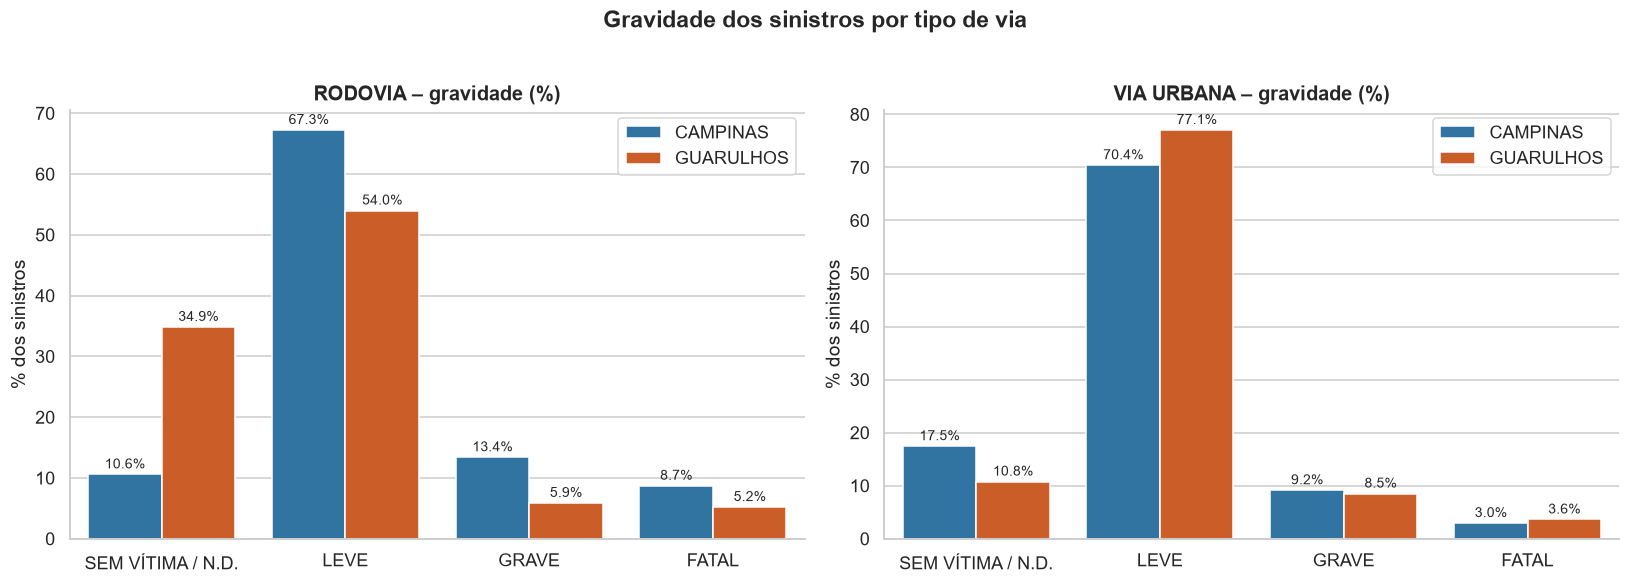

In [9]:
grav = pct_por(sin, "gravidade")
viz.salvar_tab(grav, "03_gravidade")
fig, axes = plt.subplots(1, 2, figsize=(15, 5.2))
for ax, via in zip(axes, VIAS):
    sns.barplot(data=grav[grav.grupo_via == via], x="gravidade", y="pct", hue="municipio",
                order=config.ORDEM_GRAVIDADE, hue_order=MUN, palette=config.CORES, ax=ax)
    viz.rotulos_pct(ax)
    ax.set(title=f"{via} – gravidade (%)", xlabel="", ylabel="% dos sinistros"); ax.legend(title="")
fig.suptitle("Gravidade dos sinistros por tipo de via", fontweight="bold", y=1.02)
plt.tight_layout(); viz.salvar_fig(fig, "03_gravidade_por_via"); plt.show()

## 8. Evolução da % de sinistros graves ou fatais

  ✔ tabela salva: reports/tables/03_evolucao_gravidade_anual.csv


  ✔ figura salva: reports/figures/03_evolucao_gravidade_anual.png


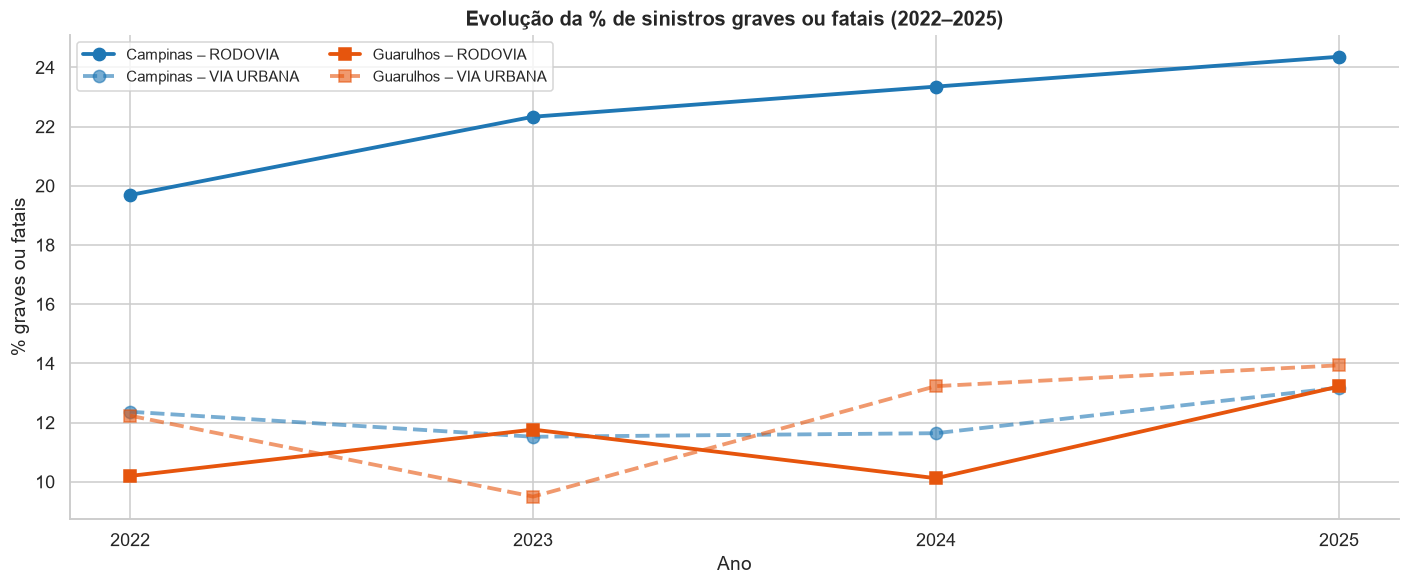

In [10]:
eg = (sin.groupby(["municipio", "grupo_via", "ano"])["grave_fatal"].mean().mul(100)
         .reset_index(name="pct_gf"))
viz.salvar_tab(eg, "03_evolucao_gravidade_anual")
fig, ax = plt.subplots(figsize=(13, 5.5))
for mun in MUN:
    for via in VIAS:
        d = eg[(eg.municipio == mun) & (eg.grupo_via == via)]
        ax.plot(d.ano, d.pct_gf, color=config.CORES[mun], lw=2.5, ms=8,
                marker="o" if mun == "CAMPINAS" else "s", ls="-" if via == "RODOVIA" else "--",
                alpha=1 if via == "RODOVIA" else .6, label=f"{mun.title()} – {via}")
ax.set(title="Evolução da % de sinistros graves ou fatais (2022–2025)", xlabel="Ano",
       ylabel="% graves ou fatais", xticks=config.ANOS)
ax.legend(ncol=2, fontsize=10)
plt.tight_layout(); viz.salvar_fig(fig, "03_evolucao_gravidade_anual"); plt.show()

## 9. Tipos de sinistro
Usa as flags `tp_sinistro_*` (um sinistro pode ter mais de um tipo; por isso as % não somam 100).
**Observação:** a coluna `tp_sinistro_colisao_traseira` está vazia em 100% dos registros do
InfoSiga 2022–2026, portanto colisão traseira não pode ser analisada.

  ✔ tabela salva: reports/tables/03_tipos_sinistro.csv


  ✔ figura salva: reports/figures/03_tipos_sinistro.png


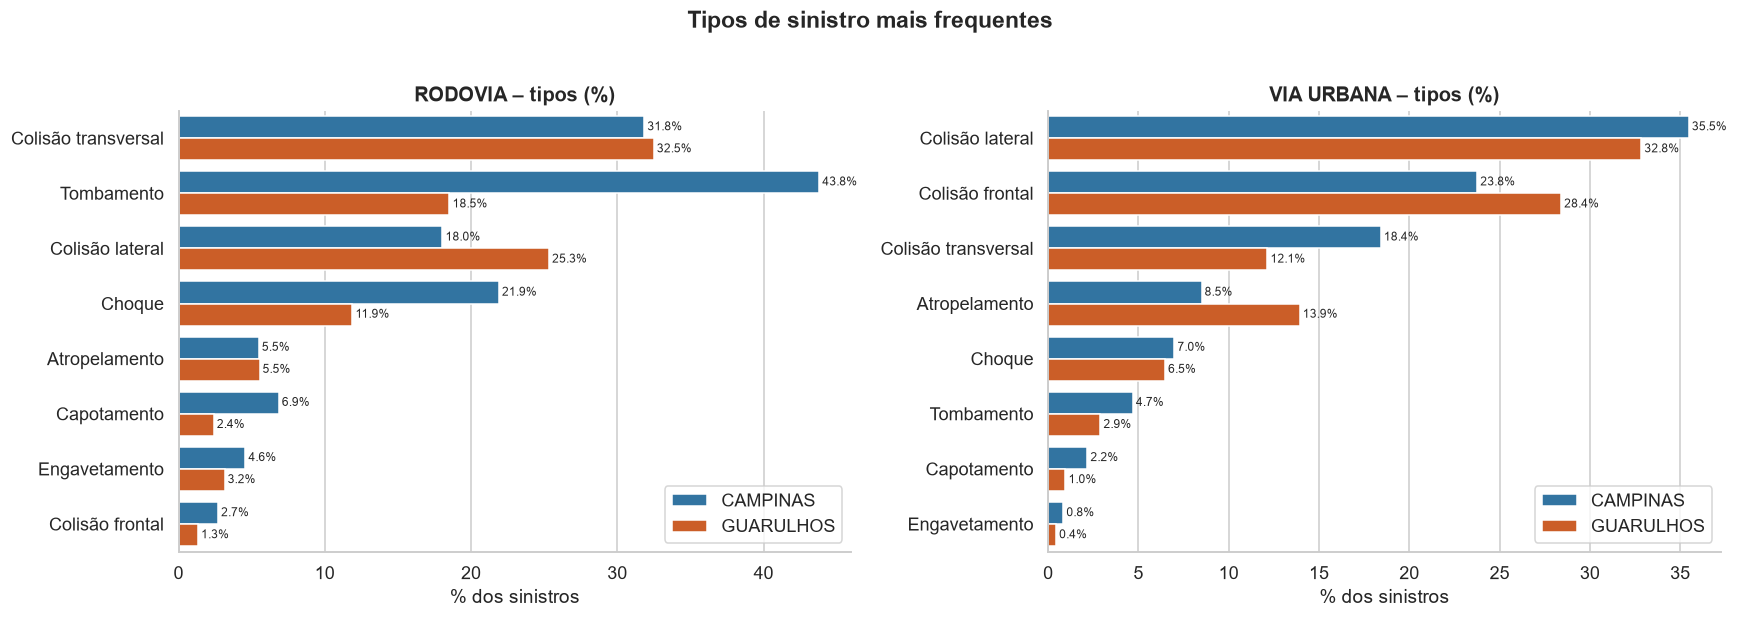

In [11]:
tipos = (sin.groupby(["grupo_via", "municipio"])[list(config.ROTULOS_TIPO)].mean().mul(100)
            .rename(columns=config.ROTULOS_TIPO).reset_index()
            .melt(id_vars=["grupo_via", "municipio"], var_name="tipo", value_name="pct"))
viz.salvar_tab(tipos, "03_tipos_sinistro")
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
for ax, via in zip(axes, VIAS):
    d = tipos[tipos.grupo_via == via]
    ordem = d.groupby("tipo").pct.mean().sort_values(ascending=False).index
    sns.barplot(data=d, y="tipo", x="pct", hue="municipio", order=ordem, hue_order=MUN,
                palette=config.CORES, ax=ax)
    viz.rotulos_pct(ax, fontsize=8)
    ax.set(title=f"{via} – tipos (%)", xlabel="% dos sinistros", ylabel=""); ax.legend(title="")
fig.suptitle("Tipos de sinistro mais frequentes", fontweight="bold", y=1.02)
plt.tight_layout(); viz.salvar_fig(fig, "03_tipos_sinistro"); plt.show()

## 10. Top vias com mais sinistros
Barra clara = todos os sinistros; barra escura = graves ou fatais.

  ✔ tabela salva: reports/tables/03_top_vias.csv


  ✔ figura salva: reports/figures/03_top_vias.png


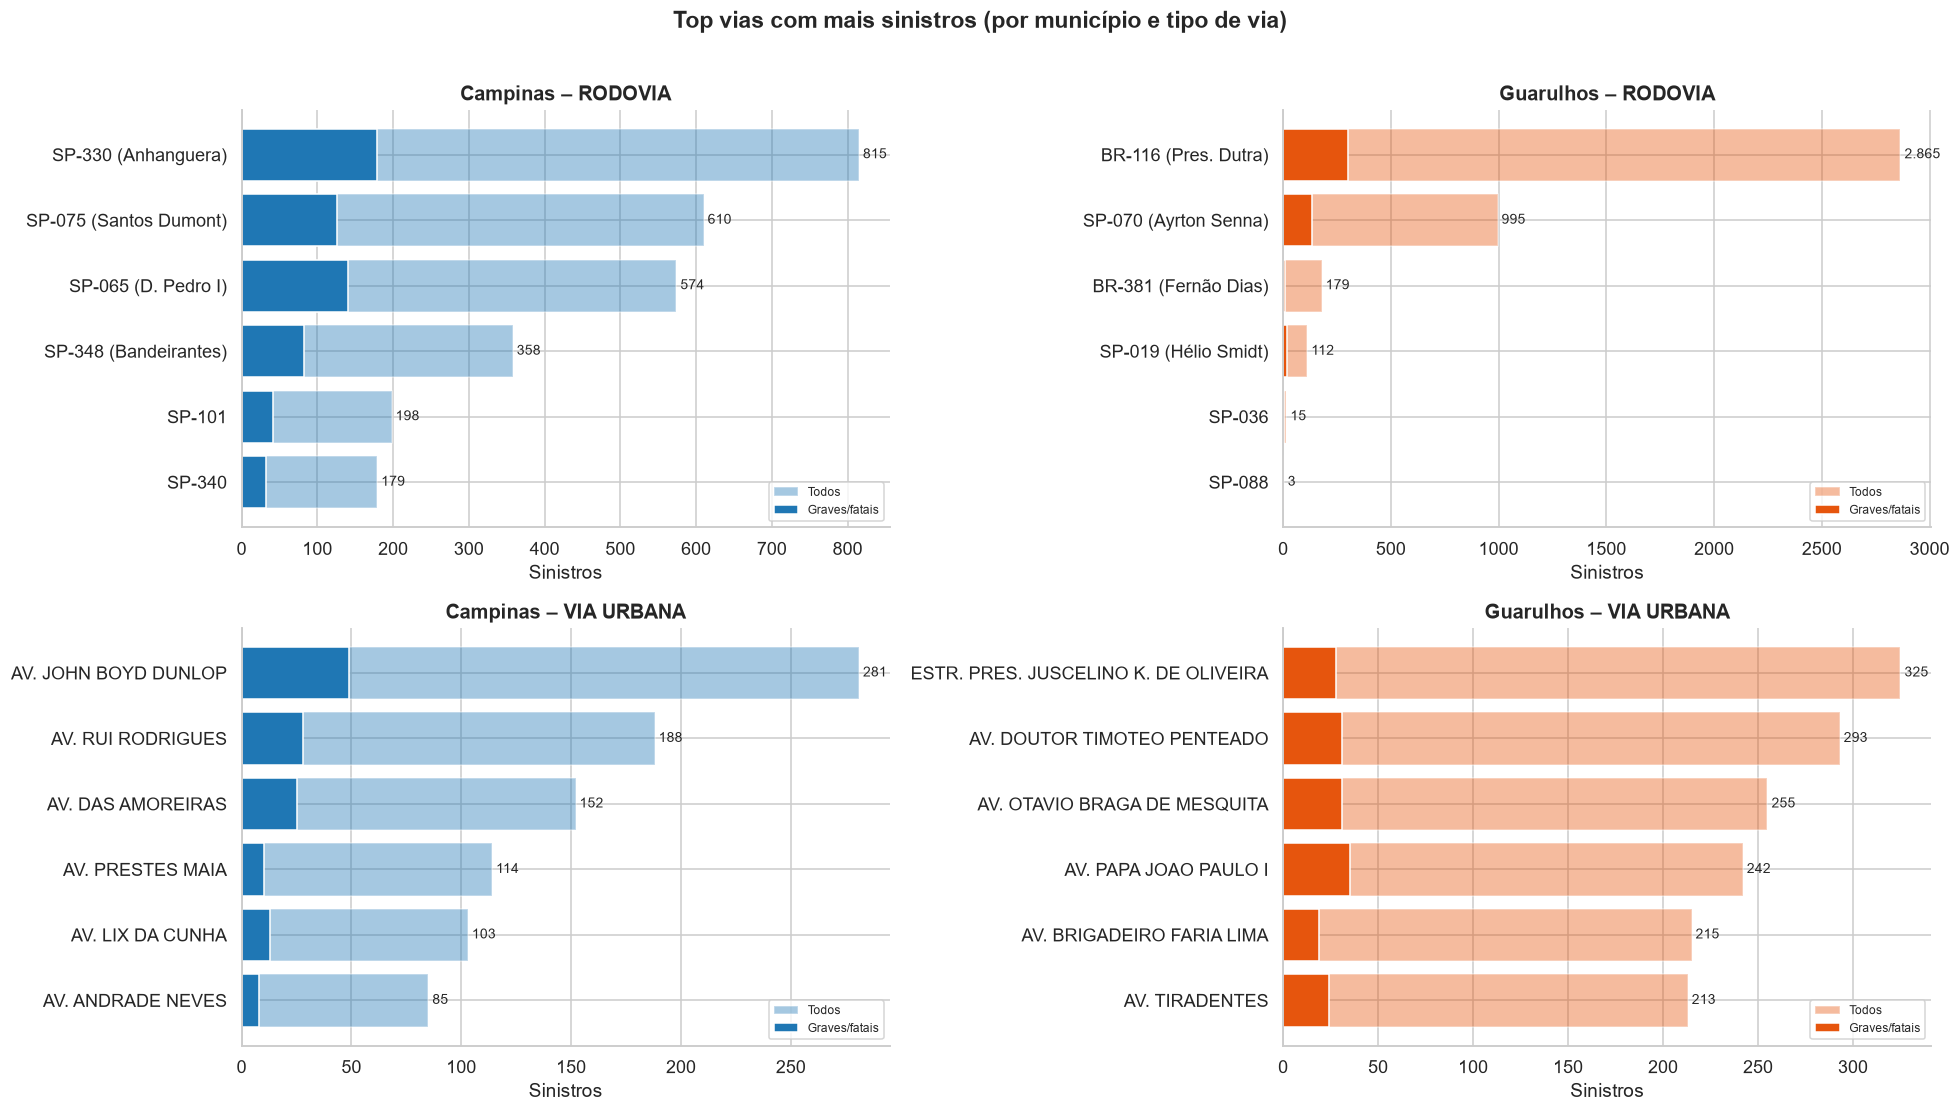

In [12]:
top = (sin[~sin.via_nome.isin(["N.D.", "OUTRA / N.D."])]
       .groupby(["municipio", "grupo_via", "via_nome"])
       .agg(sinistros=("id_sinistro", "count"), graves_fatais=("grave_fatal", "sum"), fatais=("fatal", "sum"))
       .reset_index().sort_values("sinistros", ascending=False)
       .groupby(["municipio", "grupo_via"]).head(6))
viz.salvar_tab(top, "03_top_vias")
fig, axes = plt.subplots(2, 2, figsize=(18, 10))
for i, via in enumerate(VIAS):
    for j, mun in enumerate(MUN):
        ax = axes[i, j]
        d = top[(top.municipio == mun) & (top.grupo_via == via)].sort_values("sinistros")
        ax.barh(d.via_nome, d.sinistros, color=config.CORES[mun], alpha=.4, label="Todos")
        ax.barh(d.via_nome, d.graves_fatais, color=config.CORES[mun], label="Graves/fatais")
        for y, (n, g) in enumerate(zip(d.sinistros, d.graves_fatais)):
            ax.text(n, y, f" {n:,}".replace(",", "."), va="center", fontsize=9)
        ax.set(title=f"{mun.title()} – {via}", xlabel="Sinistros"); ax.legend(fontsize=8, loc="lower right")
fig.suptitle("Top vias com mais sinistros (por município e tipo de via)", fontweight="bold", y=1.01)
plt.tight_layout(); viz.salvar_fig(fig, "03_top_vias"); plt.show()

## 11. Veículos e modos envolvidos
% dos sinistros que envolveram **motocicleta, automóvel, veículo pesado (caminhão/ônibus),
bicicleta e pedestre** (flags derivadas das colunas `qtd_*`).

  ✔ tabela salva: reports/tables/03_modos_envolvidos.csv


  ✔ figura salva: reports/figures/03_modos_envolvidos.png


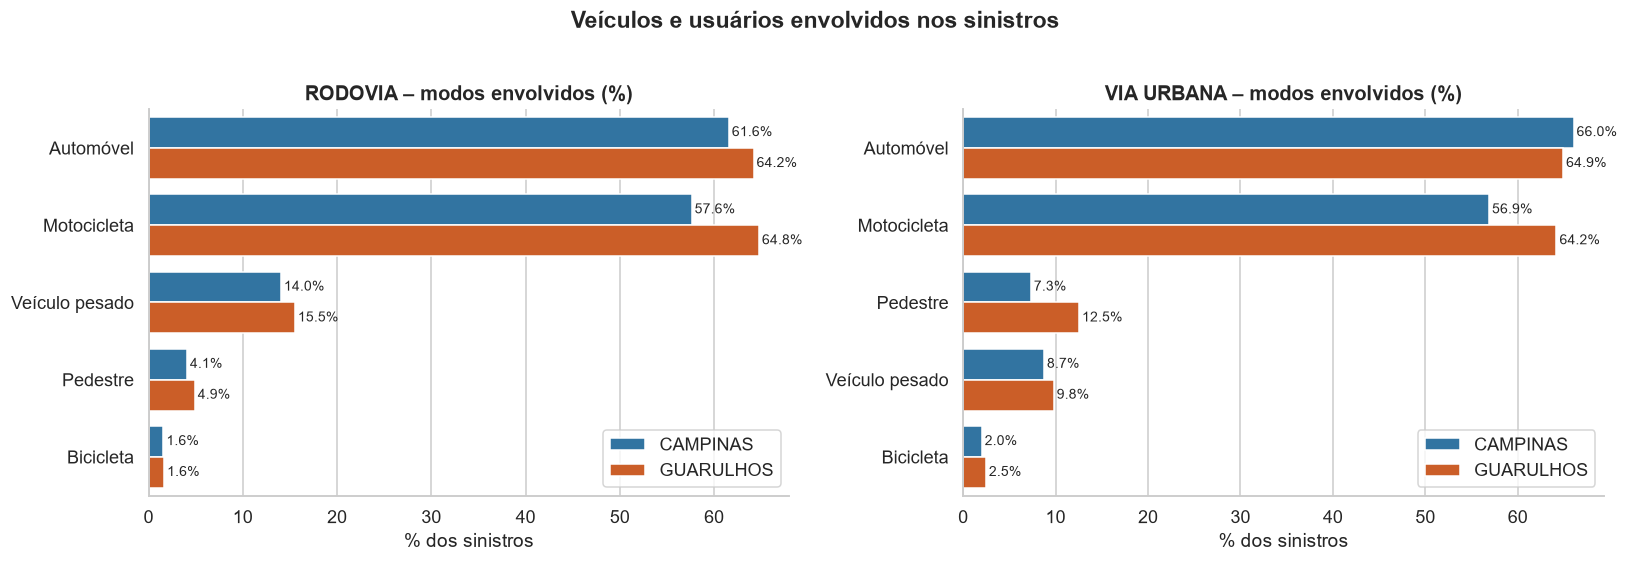

In [13]:
modos = list(config.ROTULOS_MODO)
mod = (sin.groupby(["grupo_via", "municipio"])[modos].mean().mul(100)
          .rename(columns=config.ROTULOS_MODO).reset_index()
          .melt(id_vars=["grupo_via", "municipio"], var_name="modo", value_name="pct"))
viz.salvar_tab(mod, "03_modos_envolvidos")
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for ax, via in zip(axes, VIAS):
    d = mod[mod.grupo_via == via]
    ordem = d.groupby("modo").pct.mean().sort_values(ascending=False).index
    sns.barplot(data=d, y="modo", x="pct", hue="municipio", order=ordem, hue_order=MUN,
                palette=config.CORES, ax=ax)
    viz.rotulos_pct(ax)
    ax.set(title=f"{via} – modos envolvidos (%)", xlabel="% dos sinistros", ylabel=""); ax.legend(title="")
fig.suptitle("Veículos e usuários envolvidos nos sinistros", fontweight="bold", y=1.02)
plt.tight_layout(); viz.salvar_fig(fig, "03_modos_envolvidos"); plt.show()

Evolução anual do **número** de sinistros que envolveram cada modo (um painel por modo).

  ✔ tabela salva: reports/tables/03_modos_evolucao_anual.csv


  ✔ figura salva: reports/figures/03_modos_evolucao_anual.png


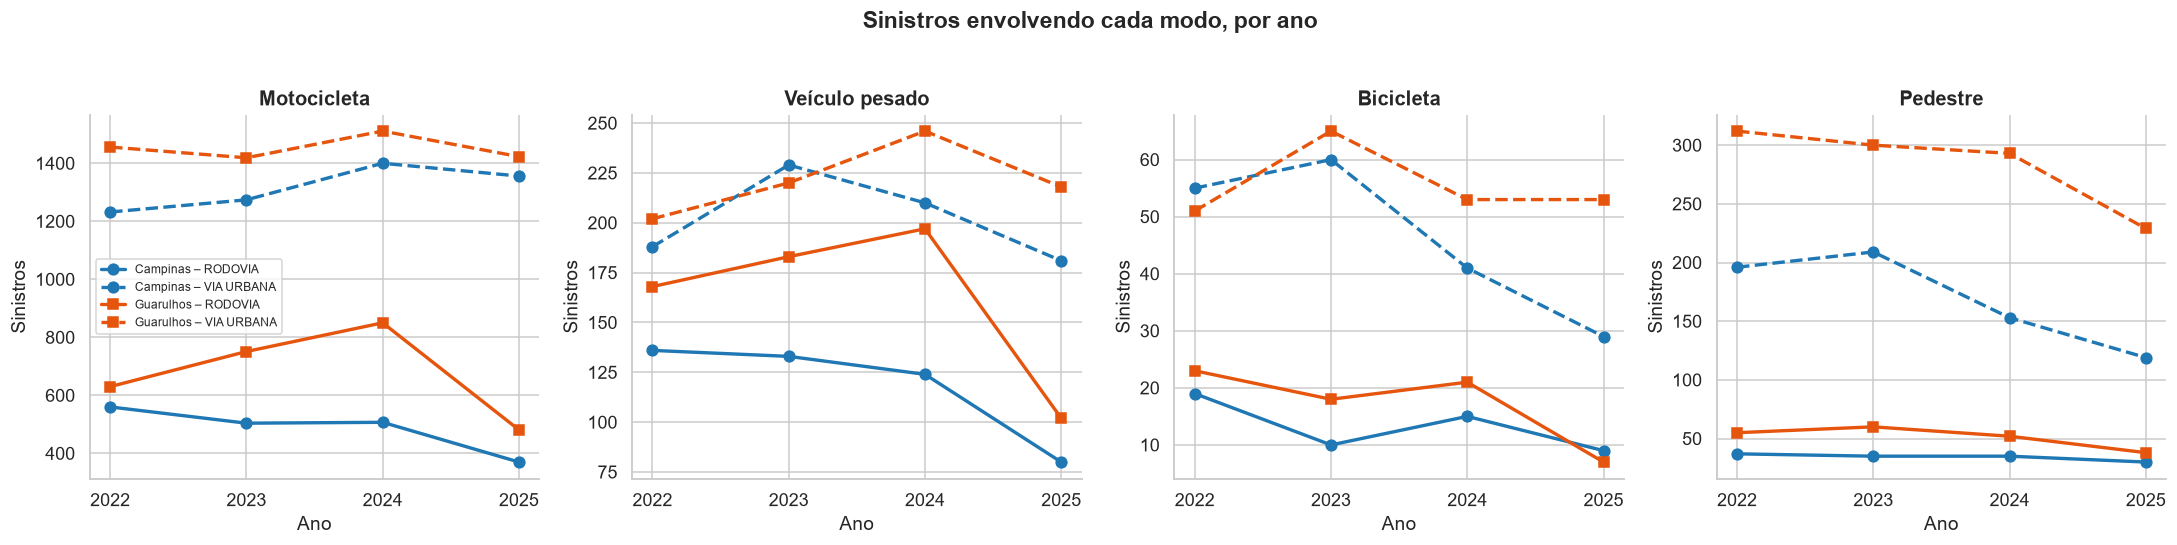

In [14]:
ma = (sin.groupby(["municipio", "grupo_via", "ano"])[["envolve_moto", "envolve_pesado",
                                                      "envolve_bicicleta", "envolve_pedestre"]]
         .sum().reset_index())
viz.salvar_tab(ma, "03_modos_evolucao_anual")
fig, axes = plt.subplots(1, 4, figsize=(20, 4.8))
for ax, m in zip(axes, ["envolve_moto", "envolve_pesado", "envolve_bicicleta", "envolve_pedestre"]):
    for mun in MUN:
        for via in VIAS:
            d = ma[(ma.municipio == mun) & (ma.grupo_via == via)]
            ax.plot(d.ano, d[m], color=config.CORES[mun], lw=2.2, ms=7,
                    marker="o" if mun == "CAMPINAS" else "s", ls="-" if via == "RODOVIA" else "--",
                    label=f"{mun.title()} – {via}")
    ax.set(title=config.ROTULOS_MODO[m], xlabel="Ano", ylabel="Sinistros", xticks=config.ANOS)
axes[0].legend(fontsize=8)
fig.suptitle("Sinistros envolvendo cada modo, por ano", fontweight="bold", y=1.03)
plt.tight_layout(); viz.salvar_fig(fig, "03_modos_evolucao_anual"); plt.show()

## Resumo automático dos achados (valores calculados acima)

In [15]:
for _, r in geral.iterrows():
    print(f"{r.municipio:<10} {r.grupo_via:<10}: {r.sinistros:>6,} sinistros | "
          f"{r.pct_gf:.1f}% graves/fatais | {r.fatais:,} fatais ({r.pct_fatal:.1f}%)")
p = per.loc[per.groupby(["grupo_via", "municipio"]).pct.idxmax()]
print("\nPeríodo com mais sinistros:")
for _, r in p.iterrows():
    print(f"  {r.municipio:<10} {r.grupo_via:<10} → {r.periodo} ({r.pct:.1f}%)")

CAMPINAS   RODOVIA   :  3,369 sinistros | 22.1% graves/fatais | 294 fatais (8.7%)
CAMPINAS   VIA URBANA:  9,250 sinistros | 12.1% graves/fatais | 274 fatais (3.0%)
GUARULHOS  RODOVIA   :  4,188 sinistros | 11.1% graves/fatais | 219 fatais (5.2%)
GUARULHOS  VIA URBANA:  9,051 sinistros | 12.2% graves/fatais | 329 fatais (3.6%)

Período com mais sinistros:
  CAMPINAS   RODOVIA    → Manhã (32.3%)
  GUARULHOS  RODOVIA    → Manhã (36.0%)
  CAMPINAS   VIA URBANA → Tarde (33.6%)
  GUARULHOS  VIA URBANA → Noite (31.0%)
